# 14-T800仿真调试策略


## 1. 本课主题：日志为王

本篇对应《具身智能机器人实战》第 14 节《T800 仿真调试策略》，副标题为“日志为王”。前几节串起了状态观测、策略动作与目标关节角，本节关注这些环节出问题时，怎样获得可供分析的依据。

**资料依据：**[课程百度网盘资料](https://pan.baidu.com/s/1TI1Opoqy_jjmWCzhUOwliw?pwd=1234)，提取码 `1234`。已逐页核对 `ppt/14_仿真调试策略.pptx` 全部 3 页：第 1 页给出主题，第 2 页用示意图对比调试方式，第 3 页为品牌结束页。

这份课件以调试理念和图片为主，没有列出日志字段、记录代码、文件路径或参数调整步骤。下文先整理图中表达的要点，再用少量“工程补充”联系前几节内容。未转录配套视频 `14_T800仿真调试策略.mp4`，也未读取网盘中的 `code.zip`。


## 2. 用日志和曲线分析仿真问题

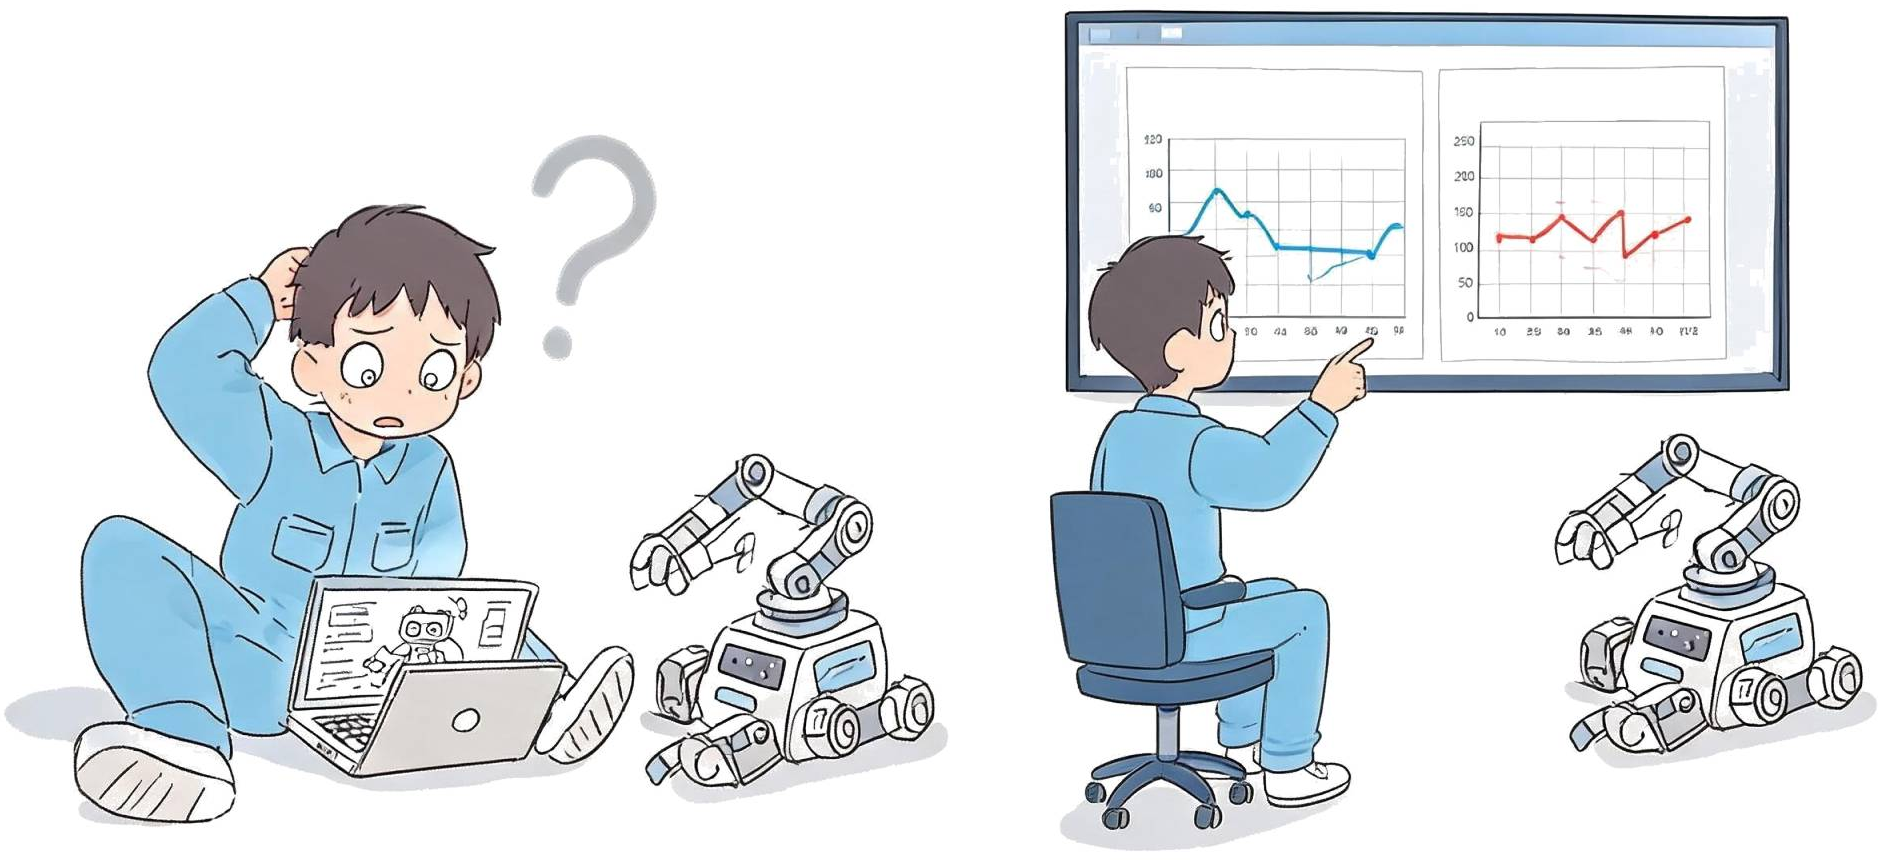

*原课件第 2 页：左侧是面对机器人和电脑无从判断，右侧是结合屏幕上的曲线进行分析。*

仿真画面能直观展示机器人是否运动、姿态是否异常，但要判断异常怎样发生，还需要查看运动过程中的数值变化。课件用两种调试场景强调：**把运行过程记录下来，再根据日志分析问题。**

日志可以保留某一时刻的输入、计算结果和状态。把连续记录画成曲线后，还可以比较变化的先后顺序，看出数值何时开始偏离预期。这样，排查就能从“画面看起来不对”推进到“哪个环节出现了什么变化”。

图中的两条曲线用于说明这种调试方式。课件没有给它们标注明确的变量名、单位和来源，因此不能把蓝线或红线直接解释成 T800 某个关节的真实角度、力矩或测试结果。


## 3. 工程补充：沿控制过程选择记录量

结合前几节的控制过程，可以先围绕一个出现问题的关节，记录同一时刻的指令和反馈。下表是帮助理解“记什么”的建议，不是课件给出的日志格式。

| 控制环节 | 可记录的量 | 用来核对什么 |
|---|---|---|
| 策略输出 | 对应关节的 `action` | 策略输出怎样变化，有没有突变或异常数值 |
| 动作转换 | `DEFAULT_Q`、`ACTION_SCALE` 与 `q_des` | 目标角是否符合第 13 节的转换公式 |
| 状态反馈 | 实测角 `q`、角速度 `dq` | 实际运动是否跟随目标，变化是否持续 |
| PD 与力矩限幅 | 限幅前力矩、限幅后控制输入 | 控制器是否长期受到力矩上限约束 |

给这些记录带上仿真时间或步号，并标明关节名称与单位，才能把目标和反馈对应起来。角度、角速度与力矩的单位不同，画图时需要明确标注。

例如关节没有按预期运动，可以先看 `q_des` 是否正确，再看它与实测 `q` 的差异。如果目标已明显异常，就沿着 `action`、基准角和缩放量检查；如果目标合理而反馈偏离，再结合 `dq` 和限幅前后的力矩分析。一次保留相同初始条件和输入命令，只调整一个待验证因素，便于比较前后记录。

这些记录提供定位线索，不能单凭一条曲线就断定故障原因。这里没有指定实际日志文件，也没有据此修改策略或控制参数。


## 4. 本课检查

本节应掌握的是：观察仿真现象后，保留相关数值和时间关系，用日志及曲线支持判断。记录目标角与实测角时，应能说明二者分别来自哪个环节，并区分角度偏差和力矩限幅。

本篇已覆盖课件主题与调试示意图。具体日志实现、视频中的操作过程及实际故障案例未在已读取的课件中展开，本篇没有补写成课程原有步骤，也没有执行 T800 仿真测试。
